# Lab 2-01：好 prompt 與壞 prompt

**目標**：同一個任務，先用一句話隨口問，再改成有結構的提示詞，然後**用數字**比較兩者差多少。

**你會學到**
- 提示詞的四段結構：角色、背景與任務、約束、示例
- 外部資料用標籤包起來，跟指令分開
- 把「格式對不對」寫成程式可以檢查的規則
- 同一題跑很多次，算一致率，而不是看一次就下結論

**前置**：模組 1 完成，本機 Ollama 有 `qwen2.5:3b`。

**對應投影片**：「Prompt 是什麼」「提示詞的四段結構」「少樣本：從示例學格式」「推理模型：定義成功」

![一句話 prompt 與四段結構各跑 5 次的輸出對照](images/prompt_before_after.jpg)

*圖：同一題跑 5 次。左邊只問一句話，五次輸出長短、格式都不同（朱紅框）；右邊用四段結構加上標籤包住的工單，五次都輸出同一行格式，程式才接得住。*

## Step 1：準備一個小幫手

`chat` 來自模組 1 寫好的 `course_utils/llm.py`。這裡再包一層，讓「一段文字進、一段文字出」更短。

In [1]:
from course_utils.llm import chat


def ask(prompt: str, temperature: float = 0.0) -> str:
    return chat([{"role": "user", "content": prompt}], temperature=temperature).strip()


print(ask("用一句話說明什麼是工單。"))

工單是一種記錄問題、需求或維護操作的單一文件或表格。


## Step 2：先看壞 prompt

情境：你在虛構公司「星帆雲端」當工程師，要把週會紀錄整理給沒參加的同事。最直覺的寫法是「總結一下」。

In [2]:
meeting = """日期：11 月 12 日（二）
與會：阿哲（SRE 主管）、小葵（後端）、Ken（客服）
阿哲：上週五晚上付款服務掛了 25 分鐘，原因是資料庫連線池設太小。
小葵：連線池已經從 20 調到 80，也加了告警，連線用量超過七成就通知。
Ken：那 25 分鐘有 37 張客訴工單，大部分是扣款成功但訂單顯示未付款。
阿哲：小葵這週五前寫事後檢討；Ken 整理受影響的訂單清單給帳務。
小葵：我想順便把慢查詢也查一下，但可能下週才有空。"""

print(ask(f"總結一下：\n{meeting}"))

根據會議記錄，以下是11月12日會議的主要內容總結：

### 會議時間與參與人員
- **日期**：11月12日（星期二）
- **與會人員**：阿哲（SRE主管）、小葵（後端）、Ken（客服）

### 主要討論點
1. **付款服務問題**
   - **阿哲**提到上週五晚上付款服務因資料庫連線池設置過小，導致服務掛起25分鐘。
   - **小葵**表示連線池已經從20增加到80，並設置了告警，當連線用量超過70%時會通知。

2. **客訴情況**
   - **阿哲**指出，25分鐘的服務問題導致有37張客訴工單，這些工單主要涉及扣款成功但訂單顯示未付款的情況。

3. **後續工作安排**
   - **小葵**提到，她會在小葵這週五前完成事後檢討報告。
   - **Ken**則負責整理受影響的訂單清單，供帳務人員參考。
   - **小葵**還提到，她會在下週有空時，順便檢查慢查詢問題。

### 總結
- **問題解決**：小葵將在小葵這週五前完成事後檢討報告，並與帳務人員分享受影響的訂單清單。
- **客訴處理**：Ken將整理並提供受影響的訂單清單，以便帳務人員進行處理。
- **問題改善**：小葵將在下週有空時，檢查慢查詢問題，以進一步提升系統性能和穩定性。


讀起來不差，但問題是：**你沒說要給誰看、要多長、要不要列待辦**，模型只好自己猜。
換個溫度再問一次，長度和格式都可能變。程式要接這種輸出，會很痛苦。

In [3]:
for i in range(2):
    out = ask(f"總結一下：\n{meeting}", temperature=1.0)
    print(f"--- 第 {i + 1} 次（{len(out)} 字）---\n{out}\n")

--- 第 1 次（451 字）---
11月12日（星期二），阿哲（SRE主管）、小葵（后端）、Ken（客服）在会议上讨论了近期付款服务出现的不稳定情况。

阿哲首先指出，上周五晚上付款服务因为数据连接池设置太小导致服务中断了25分钟。小葵随后分享说，他们已经将连接池的大小从20扩展到了80，并且已经添加了告警系统，在连接使用量超过70%时立即通知。她提到，由于这个情况，有37张客诉工单因扣款成功但订单显示未付款而被生成。

Ken则反馈了这25分钟的服务中断对客服产生的影响，指出在那25分钟里，有37张客诉工单是因为订单显示未付款而被创建。

阿哲建议小葵在本周五之前完成事后的分析，并指导Ken整理并提供受影响订单的清单给财务部门。

小葵表示，她计划在本周五之前完成事后的分析，但她提到她需要检查慢查询以优化系统性能，这可能需要等到下一周才能完成。

总结来看，这次会议的主要内容是对上次服务中断的讨论和下一步措施的规划。会议还涉及如何利用告警系统来提高服务可靠性，以及如何通过分析数据来提升客户满意度和财务工作的准确性和效率。

--- 第 2 次（295 字）---
總結如下：

1. **問題復盤與解決**：
   - **付款服務問題**：上週五晚上，支付服務因資料庫連線池設置過小，導致服務延遲25分鐘。
   - **解決方案**：連線池已經從20增加到80，並加入了告警机制。当使用量超过70%时，会进行通知。

2. **客訴管理**：
   - 上週五晚上，共有37位客訴工單，主要原因是扣款成功但訂單顯示未付款。这些工单将由小葵在本周五之前进行事後檢討。

3. **影響訂單清單**：
   - 影響的訂單清單需要由Ken整理，以便会计部门处理。

4. **其他工作**：
   - 小葵提出想对慢查询进行检查，但暂时安排在下一周进行。



## Step 3：四段結構

一則好提示詞像一份輸入規格：

```
┌──────────────┐
│ 角色          │ 你是誰、用什麼口吻
├──────────────┤
│ 背景與任務    │ 給什麼資料、要做到什麼
├──────────────┤
│ 約束          │ 不准做什麼、不確定時怎麼辦、輸出格式
├──────────────┤
│ 示例          │ 輸入 → 輸出的範本（選用）
├──────────────┤
│ <外部資料>    │ 用標籤包住，放最後
└──────────────┘
```

寫成函式，之後每次組 prompt 都用同一個模板。

In [4]:
def build_prompt(role: str, task: str, constraints: list[str], data: str,
                 examples: str = "", tag: str = "data") -> str:
    parts = [f"# 角色\n{role}", f"# 背景與任務\n{task}",
             "# 約束\n" + "\n".join(f"- {c}" for c in constraints)]
    if examples:
        parts.append(f"# 示例\n{examples}")
    parts.append(f"<{tag}>\n{data}\n</{tag}>")
    return "\n\n".join(parts)


summary_prompt = build_prompt(
    role="你是星帆雲端的 SRE，負責把會議紀錄整理給沒參加的同事。",
    task="閱讀 <meeting> 裡的週會紀錄，整理成摘要與待辦。",
    constraints=[
        "第一段用一句話講最重要的事，不超過 40 字",
        "接著列出待辦，每行格式：- [負責人] 事項（期限）；沒提期限就寫（未定）",
        "只根據紀錄內容，不要補充紀錄裡沒有的事",
        "使用繁體中文（台灣用語）",
    ],
    data=meeting,
    tag="meeting",
)
print(summary_prompt)

# 角色
你是星帆雲端的 SRE，負責把會議紀錄整理給沒參加的同事。

# 背景與任務
閱讀 <meeting> 裡的週會紀錄，整理成摘要與待辦。

# 約束
- 第一段用一句話講最重要的事，不超過 40 字
- 接著列出待辦，每行格式：- [負責人] 事項（期限）；沒提期限就寫（未定）
- 只根據紀錄內容，不要補充紀錄裡沒有的事
- 使用繁體中文（台灣用語）

<meeting>
日期：11 月 12 日（二）
與會：阿哲（SRE 主管）、小葵（後端）、Ken（客服）
阿哲：上週五晚上付款服務掛了 25 分鐘，原因是資料庫連線池設太小。
小葵：連線池已經從 20 調到 80，也加了告警，連線用量超過七成就通知。
Ken：那 25 分鐘有 37 張客訴工單，大部分是扣款成功但訂單顯示未付款。
阿哲：小葵這週五前寫事後檢討；Ken 整理受影響的訂單清單給帳務。
小葵：我想順便把慢查詢也查一下，但可能下週才有空。
</meeting>


In [5]:
print(ask(summary_prompt))

### 摘要
上週五晚上付款服務因資料庫連線池設置過小導致掛起 25 分鐘，造成 37 張客訴工單。

### 待辦
- [阿哲] 上週五前寫事後檢討（未定）
- [小葵] 下週五前寫事後檢討；整理受影響的訂單清單給帳務（未定）
- [小葵] 下週五前寫事後檢討；把慢查詢也查一下（未定）


差別在哪裡：
- 壞 prompt 的輸出常混進簡體字；這裡把「使用繁體中文」寫進約束。小模型偶爾還是會漏，這是「要求」不是「保證」。
- 長度和格式被鎖住了，程式可以用 `- [` 開頭找出每一條待辦。
- 「沒提期限就寫（未定）」是**不確定時怎麼辦**的規則，少了它，模型會自己編一個期限。
- **對照原文檢查負責人和期限。** 小模型常把「說話的人」當成「負責人」（阿哲說「小葵這週五前寫檢討」，負責人是小葵）。結構讓輸出好讀，不代表內容一定對。
- 紀錄放在 `<meeting>` 裡，模型比較不會把紀錄裡的句子當成指令（Lab 2-04 會專門攻擊這一點）。

## Step 4：少樣本——用示例鎖格式

換一個更需要固定格式的任務：工單分流。輸出要給程式讀，所以格式必須一模一樣：

`類別=<網路/資料庫/帳號/帳務>；優先=<P1/P2/P3>`

先試只用文字描述格式（zero-shot），再試附上兩個範例（few-shot）。

In [6]:
TRIAGE_ROLE = "你是星帆雲端的工單分流員。"
TRIAGE_TASK = "判斷 <ticket> 裡的工單屬於哪一類，並給優先度。"
TRIAGE_RULES = [
    "類別只能是：網路、資料庫、帳號、帳務",
    "優先度只能是 P1、P2、P3（P1 最急：影響很多人或影響收錢）",
    "只輸出一行，格式：類別=<類別>；優先=<P1/P2/P3>",
    "不要解釋，不要加任何其他文字",
]
TRIAGE_SHOTS = """<ticket>VPN 連不上公司內網，整個團隊都卡住</ticket>
類別=網路；優先=P1

<ticket>想把發票抬頭改成新公司名稱</ticket>
類別=帳務；優先=P3"""

ticket = "新進同事登入後台顯示權限不足，看不到報表頁"

zero_shot = build_prompt(TRIAGE_ROLE, TRIAGE_TASK, TRIAGE_RULES, ticket, tag="ticket")
few_shot = build_prompt(TRIAGE_ROLE, TRIAGE_TASK, TRIAGE_RULES, ticket,
                        examples=TRIAGE_SHOTS, tag="ticket")
print("zero-shot →", ask(zero_shot))
print("few-shot  →", ask(few_shot))

zero-shot → 類別=帳號；優先=P2
few-shot  → 類別=帳號；優先=P2


## Step 5：把「格式對」寫成程式

「推理模型：定義成功」那頁說：先把「對」的標準寫清楚。最清楚的寫法就是一段程式。
這裡用正規表示式：整行必須完全符合，多一個字都算錯。

In [7]:
import re

FORMAT = re.compile(r"^類別=(網路|資料庫|帳號|帳務)；優先=(P[123])$")


def check(output: str) -> tuple[bool, str | None]:
    """回傳（格式對不對, 抓到的類別）。"""
    m = FORMAT.match(output.strip())
    return (True, m.group(1)) if m else (False, None)


for out in ["類別=帳號；優先=P2", "類別：帳號，優先：P2", "這張工單屬於帳號問題。\n類別=帳號；優先=P2"]:
    print(check(out), repr(out))

(True, '帳號') '類別=帳號；優先=P2'
(False, None) '類別：帳號，優先：P2'
(False, None) '這張工單屬於帳號問題。\n類別=帳號；優先=P2'


## Step 6：同題跑 5 次，算一致率

看一次就下結論很危險：溫度大於 0 時，同一個 prompt 每次輸出都可能不同。
這裡用 4 張有標準答案的工單，每種 prompt 各跑 5 次（溫度 1.0，故意放大隨機性），共 4 種 prompt：

| 版本 | 內容 |
|---|---|
| 壞 | 「這張工單是什麼問題？」 |
| 只給選項 | 一句話講類別選項和格式，沒有結構 |
| 四段結構 | `build_prompt`，zero-shot |
| 四段＋示例 | 再加兩個範例 |

這一格會打 80 次模型，約 1～2 分鐘。

In [8]:
labeled = [
    ("付款頁一直轉圈，信用卡扣款成功但訂單顯示未付款", "帳務"),
    ("從新加坡機房連到台北的 API 延遲飆到 2 秒，ping 會掉封包", "網路"),
    ("新進同事登入後台顯示權限不足，看不到報表頁", "帳號"),
    ("訂單資料表查詢很慢，慢查詢日誌一直跳出同一條 SQL", "資料庫"),
]

variants = {
    "壞": lambda t: f"這張工單是什麼問題？\n{t}",
    "只給選項": lambda t: f"把這張工單分成網路、資料庫、帳號、帳務其中一類，並給 P1～P3 優先度，"
                         f"格式：類別=X；優先=PN。工單：{t}",
    "四段結構": lambda t: build_prompt(TRIAGE_ROLE, TRIAGE_TASK, TRIAGE_RULES, t, tag="ticket"),
    "四段＋示例": lambda t: build_prompt(TRIAGE_ROLE, TRIAGE_TASK, TRIAGE_RULES, t,
                                     examples=TRIAGE_SHOTS, tag="ticket"),
}

RUNS = 5
results = {}  # 版本 → [(格式對, 類別對, 原始輸出)]
for name, make in variants.items():
    rows = []
    for text, gold in labeled:
        for _ in range(RUNS):
            out = ask(make(text), temperature=1.0)
            ok, cat = check(out)
            rows.append((ok, cat == gold, out))
    results[name] = rows
    n = len(rows)
    print(f"{name:6s} 格式一致 {sum(r[0] for r in rows):2d}/{n}　類別正確 {sum(r[1] for r in rows):2d}/{n}")

壞      格式一致  0/20　類別正確  0/20
只給選項   格式一致  4/20　類別正確  2/20
四段結構   格式一致 15/20　類別正確 14/20
四段＋示例  格式一致 20/20　類別正確 19/20


畫成長條圖。灰色是「格式一致率」，藍色是「格式對而且類別也對」。

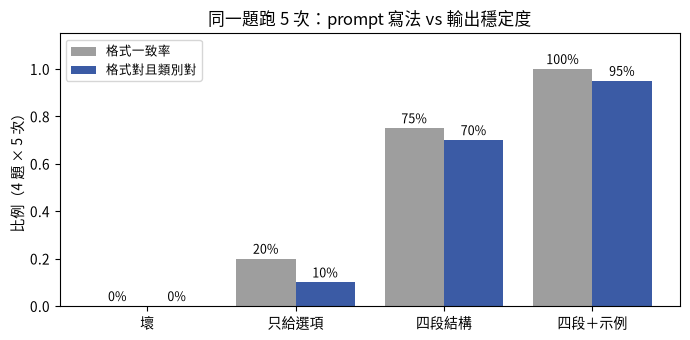

In [9]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

names = list(results)
fmt_rate = [sum(r[0] for r in results[n]) / len(results[n]) for n in names]
acc_rate = [sum(r[1] for r in results[n]) / len(results[n]) for n in names]

x = range(len(names))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([i - 0.2 for i in x], fmt_rate, width=0.4, color="#9e9e9e", label="格式一致率")
ax.bar([i + 0.2 for i in x], acc_rate, width=0.4, color="#3b5ba5", label="格式對且類別對")
for i, (f, a) in enumerate(zip(fmt_rate, acc_rate)):
    ax.text(i - 0.2, f + 0.02, f"{f:.0%}", ha="center", fontsize=9)
    ax.text(i + 0.2, a + 0.02, f"{a:.0%}", ha="center", fontsize=9)
ax.set_xticks(list(x), names)
ax.set_ylim(0, 1.15)
ax.set_ylabel("比例（4 題 × 5 次）")
ax.set_title("同一題跑 5 次：prompt 寫法 vs 輸出穩定度")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## Step 7：看失敗長什麼樣

數字只告訴你「錯多少」，要改 prompt 得看「錯成什麼樣」。每個版本各挑兩個不合格的輸出印出來。

In [10]:
for name, rows in results.items():
    bad = [r[2] for r in rows if not r[0]][:2]
    wrong = [r[2] for r in rows if r[0] and not r[1]][:1]
    print(f"=== {name}")
    for out in bad:
        print("  格式不合：", repr(out[:70]))
    for out in wrong:
        print("  類別答錯：", repr(out))

=== 壞
  格式不合： '這個工單描述的是客戶遇到的一個問題：客戶使用信用卡進行付款時，信用卡扣款成功了，但是客戶的訂單頁面顯示還沒有付款成功。這種情況可能會導致客戶'
  格式不合： '這張工單涉及的問題可能是用戶使用信用卡付款的情況下，信用卡扣款已經成功，但平台或系統顯示用戶的訂單狀態為未付款，導致用戶可能誤以為付款未能成'
=== 只給選項
  格式不合： '針對這張工單，可以歸類為**P3；類別=網路**。\n\n解析：\n- **類別=網路**：因為問題出現在付款頁面，導致一直轉圈，並不是來自資料庫'
  格式不合： '根據您的描述，這個工單似乎與信用卡扣款相關，即使付款頁一直在轉圈。信用卡扣款成功表明付款已經完成，問題似乎出在訂單顯示未付款的情況上。這通常'
  類別答錯： '類別=網路；優先=P2'
=== 四段結構
  格式不合： '帳號=帳號；優先=P1'
  格式不合： '帳號=<類別>；優先=P1'
  類別答錯： '類別=帳號；優先=P1'
=== 四段＋示例
  類別答錯： '類別=帳號；優先=P1'


幾個常見觀察（你的數字可能不同）：
- 「壞」版本格式幾乎全錯，因為根本沒說要什麼格式；這不是模型笨，是規格沒給。
- 只在一句話裡講格式，3B 模型多半還是先寫一段解釋；分段寫清楚約束後，格式一致率大幅上升。
- 示例通常讓格式更穩；類別有沒有更準，**要量了才知道**。
- 類別答錯通常集中在邊界案例（扣款成功但訂單未付款，算帳務還是資料庫？）。這種時候該改的是約束裡的定義，Lab 2-06 會用更多標註資料來比。

## 試試看

1. 把 `TRIAGE_RULES` 裡「不要解釋」那一條拿掉，重跑 Step 6，看格式一致率掉多少。
2. 在約束裡加一條類別定義（例如「扣款、發票、退款都算帳務」），看「類別正確」有沒有變化。
3. 把溫度改成 0 重跑 Step 6。一致率變成多少？這代表溫度 0 就不需要好 prompt 了嗎？

## 小結

- 提示詞是一份輸入規格：角色、背景與任務、約束、示例，外部資料用標籤包在最後。
- 「好不好」要用數字說：把格式寫成程式檢查，同題跑多次算一致率。
- 格式靠 prompt 只能「要求」，不能「保證」。下一本 Lab 2-02 先看怎麼讓模型多想幾步把答案算對；Lab 2-03 再處理怎麼保證格式。